# 2. Galactic binaries: search and parameter estimation

**Goal:** generate narrow-band TDI data, maximise the $\mathcal F$-statistic,
subtract a signal, then fit one source or the sum of two sources with nessai.

We use one year of Taiji A2/E2 near 4 mHz. **Optimal A/E SNR: GB 1 = 55;
GB 2 = 40.** 

In [1]:
%matplotlib inline
# Paths and plotting defaults only; the scientific workflow is below.
from tutorial_tools.common import DATA, OUTPUT, ORBIT, DAY, load_arrays, inner
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Parallel workers, following the Triangle-GB examples: the "fork" start
# method lets the notebook-defined functions and likelihood classes reach the
# child processes on macOS. tutorial_tools.common already pins the BLAS thread
# counts to 1, one thread per worker.
import multiprocessing
if multiprocessing.get_start_method(allow_none=True) != "fork":
    multiprocessing.set_start_method("fork", force=True)
NPROC = multiprocessing.cpu_count()
print("CPU cores:", NPROC, "| start method:", multiprocessing.get_start_method())


CPU cores: 12 | start method: fork


In [ ]:
RUN_SEARCH = True
# Nested sampling is opt-in: the default reuses the stored posterior draws in
# data/. Set RUN_INFERENCE = True to sample again (about one hour on 12 cores).
RUN_INFERENCE = False
meta = json.loads((DATA/"gb_sequential_search.json").read_text())

## 1. Initialise the native TDI waveform generator
`TDIFlyGB` computes a sparse time-domain envelope and its Fourier transform.
Generate XYZ, convert to A/E, and place the result on a chosen Fourier band.
The narrow-band PSD is approximated by its value at 4 mHz, as in the native
search example. All angles are in radians; times are in seconds.

In [3]:
from Triangle.Orbit import Orbit
from Triangle.TDI import TDIStringManipulation
from Triangle_GB.TDIFly import TDIFly, TDIFlyGB

T, dt, center = 365.25*DAY, 60., 0.004
orbit = Orbit(OrbitDir=str(ORBIT))
X = TDIFly.X2_strings
Y = TDIStringManipulation.TDIStringCyc(X)
Z = TDIStringManipulation.TDIStringCyc(Y)
gen = TDIFlyGB(orbit=orbit, Pstring_list=[X, Y, Z],
               tcb_times=np.arange(int(T/dt))*dt, Nsparse=512,
               use_gpu=False, drop_points=1)
bins = np.arange(round(center*T)-60, round(center*T)+111)
first, last = int(bins[0]), int(bins[-1])
f, S = bins/T, float(gen.PSD_A2(center))
weight = 4/T/S

def generate_AE_waveform(p):
    """A2 waveform on the analysis band for one physical parameter dictionary."""
    xyz = gen(parameters=p, domain="frequency")
    ae = gen.XYZtoAE(xyz)
    return np.asarray(gen.fill_fftseries(ae, gen.start_idx, first, last))[:, 0]


PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No pyseobnr.
no cupy 
no cupy 


## 2. Simulate one-source and two-source data
The amplitudes below give SNRs 55 and 40 with this PSD and analysis band.
For each positive-frequency bin, the real and imaginary noise components
have variance $TS/4$. Add the same noise to $h_1$ and to $h_1+h_2$.

In [4]:
p1 = dict(A=4.900209380925449e-23, f0=0.00400000855578371, fdot0=2e-16,
          phase0=0.8, inclination=1.1, longitude=4.5, latitude=-0.3, psi=0.7)
p2 = dict(A=2.9638472393920797e-23, f0=0.004000578941364363, fdot0=3e-16,
          phase0=2., inclination=0.9, longitude=1.8, latitude=0.45, psi=0.2)
injections = [p1, p2]
h1, h2 = generate_AE_waveform(p1), generate_AE_waveform(p2)
rng = np.random.default_rng(20261111)
noise = np.sqrt(T*S/4)*(rng.normal(size=h1.shape)+1j*rng.normal(size=h1.shape))
single_data, two_data = h1+noise, h1+h2+noise
print("Injected A/E SNRs:", [np.sqrt(inner(h, h, weight)) for h in (h1, h2)])

# Verify the data match those used by the supplied long-run posteriors.
reference = load_arrays("gb_sequential_search.npz")
for name, d in [("single_data", single_data), ("two_data", two_data)]:
    np.testing.assert_allclose(d, reference[name], rtol=1e-10, atol=1e-28)


Injected A/E SNRs: [55.00000000000001, 40.0]


## 3. One source: search and reconstruct
The $\mathcal F$-statistic maximises four linear amplitude coefficients.
Differential evolution searches four coordinates, `bounds` in the cell below:

- $f_0 = 4\,\mathrm{mHz} + \Delta$ with $\Delta$ counted in Fourier bins of
  $1/T = 0.0317\,\mu$Hz: $[-18, +18]$ bins, i.e. $\pm 0.57\,\mu$Hz. The
  two-source search widens this to $[-18, +38]$ bins ($-0.57$ to
  $+1.20\,\mu$Hz) to contain both injections.
- $\dot f_0 \in [0, 6]\times10^{-16}$ Hz/s.
- Longitude $\lambda \in [0, 2\pi)$ rad.
- $\sin\beta \in [-0.99, 0.99]$; the poles are excluded because the longitude
  becomes degenerate there.


In [5]:
from scipy.optimize import differential_evolution
from tqdm.auto import tqdm
data_to_search = single_data

def search_cost(x):
    p = dict(f0=center+x[0]/T, fdot0=x[1]*1e-16,
             longitude=x[2], latitude=np.arcsin(x[3]))
    return -float(np.asarray(gen.Fstatistics(data_to_search, p,
                  StartBound=first, EndBound=last, Tobs=T, S=S)).item())

def unpack(x):
    """Search coordinates -> physical parameters."""
    return dict(f0=center+x[0]/T, fdot0=x[1]*1e-16,
                longitude=x[2], latitude=np.arcsin(x[3]))

histories = {}  # label -> best F-statistic of every generation

def run_search(bounds, seed, label, maxiter=220, workers=-1):
    """Differential evolution on all cores, with progress bar and history."""
    history = histories[label] = []              # reset if run twice
    bar = tqdm(total=maxiter, desc=label, unit="gen")
    def callback(xk, convergence=None):
        F, p = -search_cost(xk), unpack(xk)      # best member so far
        history.append(F)
        bar.set_postfix_str(f"F={F:6.1f}  f0={p['f0']*1e3:.6f} mHz  "
                            f"conv={convergence:.1e}")
        bar.update(1)
        return False                             # never stop early
    result = differential_evolution(search_cost, bounds, seed=seed, popsize=16,
                                    maxiter=maxiter, strategy="best1exp",
                                    tol=2e-7, workers=workers, callback=callback)
    bar.close()
    p = unpack(result.x)
    print(f"  best F = {-result.fun:.2f} after {result.nit} generations: "
          f"f0 = {p['f0']:.9f} Hz, fdot0 = {p['fdot0']/1e-16:.2f}e-16 Hz/s, "
          f"lon = {p['longitude']:.3f}, lat = {p['latitude']:.3f} rad")
    return result

bounds = [(-18, 18), (0, 6), (0, 2*np.pi), (-0.99, 0.99)]
p_fit = meta["single_search"]["parameters"].copy()
if RUN_SEARCH:
    result = run_search(bounds, 20261112, "single GB")
    p_fit = unpack(result.x)
    print(result.message)
h_fit = np.asarray(gen.Fstatistics(data_to_search, p_fit, StartBound=first,
                  EndBound=last, Tobs=T, S=S, return_recovered_wave=True))[:, 0]
residual = single_data-h_fit
print("F at the recovered location:", float(np.asarray(gen.Fstatistics(
      single_data, p_fit, StartBound=first, EndBound=last, Tobs=T, S=S)).item()))


single GB:   0%|          | 0/220 [00:00<?, ?gen/s]

/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/scipy/optimize/_differentialevolution.py:487: UserWarning: differential_evolution: the 'workers' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


  best F = 1488.37 after 99 generations: f0 = 0.004000012 Hz, fdot0 = 0.00e-16 Hz/s, lon = 4.499, lat = -0.319 rad
Optimization terminated successfully.
F at the recovered location: 1488.3676923292678


## 4. Two sources: search → subtract → search again
Search the original two-source data, subtract the reconstructed waveform,
then search the residual. Later, the joint posterior fits $h_1+h_2$ to the
**original data**, preserving correlations between the two signals.
Source count and frequency band are known in this exercise.

In [6]:
data_to_search = two_data.copy()
fits = []
for step, key in enumerate(("first_search", "second_search")):
    p_step = meta[key]["parameters"].copy()
    if RUN_SEARCH:
        result = run_search([(-18, 38), *bounds[1:]], 20261113+step,
                            f"two GBs, pass {step+1}")
        p_step = unpack(result.x)
    h_step = np.asarray(gen.Fstatistics(data_to_search, p_step, StartBound=first,
                      EndBound=last, Tobs=T, S=S, return_recovered_wave=True))[:, 0]
    fits.append(h_step)
    data_to_search -= h_step
final_residual = data_to_search
print("Two-source residual norm squared:", inner(final_residual, final_residual, weight))


two GBs, pass 1:   0%|          | 0/220 [00:00<?, ?gen/s]

  best F = 1546.43 after 107 generations: f0 = 0.004000010 Hz, fdot0 = 1.32e-16 Hz/s, lon = 4.502, lat = -0.306 rad


two GBs, pass 2:   0%|          | 0/220 [00:00<?, ?gen/s]

  best F = 795.23 after 118 generations: f0 = 0.004000575 Hz, fdot0 = 6.00e-16 Hz/s, lon = 1.810, lat = 0.464 rad
Two-source residual norm squared: 637.2030083862207


### Search convergence


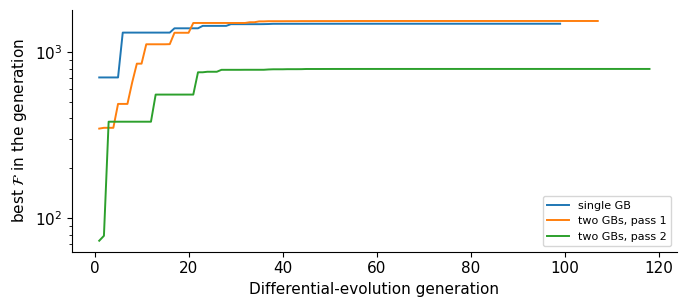

In [7]:
# Convergence of the three searches: best member of each generation.
if histories:
    fig, ax = plt.subplots(figsize=(7., 3.2))
    for label, h in histories.items():
        ax.semilogy(np.arange(1, len(h)+1), h, lw=1.4, label=label)
    ax.set(xlabel="Differential-evolution generation",
           ylabel=r"best $\mathcal{F}$ in the generation")
    ax.legend(fontsize=8)
    plt.tight_layout()
else:
    print("Search skipped (RUN_SEARCH = False); rerun it to record convergence.")


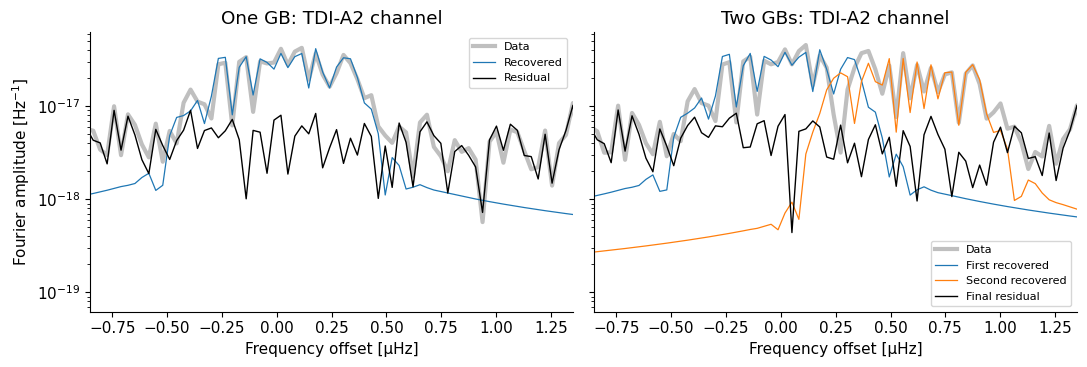

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
curves = [[(single_data, "Data"), (h_fit, "Recovered"), (residual, "Residual")],
          [(two_data, "Data"), (fits[0], "First recovered"),
           (fits[1], "Second recovered"), (final_residual, "Final residual")]]
for ax, group, title in zip(axes, curves, ("One GB: TDI-A2 channel", "Two GBs: TDI-A2 channel")):
    for h, label in group:
        if label == "Data": 
            ax.semilogy((f-center)*1e6, abs(h[0]), lw=3, label=label, color="grey", alpha=0.5)
        elif label in ["Residual", "Final residual"]: 
            ax.semilogy((f-center)*1e6, abs(h[0]), lw=1, label=label, color="k")
        else: 
            ax.semilogy((f-center)*1e6, abs(h[0]), lw=0.9, label=label)
    ax.set(xlabel="Frequency offset [µHz]", title=title, xlim=(-0.85, 1.35))
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"Fourier amplitude [Hz$^{-1}$]")
plt.tight_layout()

## 5. Write a Gaussian likelihood for one or two GBs

In [9]:
import bilby
names = ["f0", "fdot0", "longitude", "latitude", "A", "inclination", "phase0", "psi"]

class GBLikelihood(bilby.Likelihood):
    def __init__(self, data, n_sources):
        super().__init__(parameters={f"{k}_{j}": None
                         for j in range(1, n_sources+1) for k in names})
        self.data, self.n_sources = data, n_sources

    def log_likelihood(self):
        h = np.zeros_like(self.data)
        for j in range(1, self.n_sources+1):
            p = {k: self.parameters[f"{k}_{j}"] for k in names}
            h += generate_AE_waveform(p)
        r = self.data-h
        return -0.5*inner(r, r, weight)

likelihoods = [GBLikelihood(single_data, 1), GBLikelihood(two_data, 2)]
for likelihood in likelihoods:
    for j, p in enumerate(injections[:likelihood.n_sources], 1):
        likelihood.parameters.update({f"{k}_{j}": p[k] for k in names})
    print(likelihood.n_sources, "source(s): log L at injection =", likelihood.log_likelihood())
native_value = gen.Likelihood(single_data, p1, first, last, T, S)[0]
np.testing.assert_allclose(likelihoods[0].log_likelihood(), native_value, atol=1e-8)


1 source(s): log L at injection = -316.3110081668827
2 source(s): log L at injection = -316.3110081668827


### Set physical priors explicitly
Eight parameters per source, sampled in physical coordinates (nothing is
transformed). Frequency and sky use local windows around the completed search
positions stored in `gb_matched_single.json` and
`gb_matched_double_midphase.json`; the prior *forms* are the same for the
one-source and the joint run.

| parameter | prior | GB 1 | GB 2 |
|---|---|---|---|
| $f_0$ | uniform, $\pm3$ Fourier bins ($3/T=0.095\,\mu$Hz) | $4.000000\pm0.000095$ mHz | $4.000575\pm0.000095$ mHz |
| $\dot f_0$ | uniform | $[0,\,15]\times10^{-16}$ Hz/s | $[0,\,15]\times10^{-16}$ Hz/s |
| $\lambda$ | uniform, centre $\pm0.35$ rad | $[4.149,\,4.850]$ rad | $[1.460,\,2.160]$ rad |
| $\beta$ | `Cosine`: $p\propto\cos\beta$ on the box | $[-0.599,\,-0.064]$ rad | $[0.199,\,0.772]$ rad |
| $A$ | log-uniform, centre $\times/\div5$ | $[1.02,\,25.5]\times10^{-23}$ | $[0.602,\,15.1]\times10^{-23}$ |
| $\iota$ | `Sine`: uniform in $\cos\iota$ | isotropic, $[0,\pi]$ | isotropic, $[0,\pi]$ |
| $\varphi_0$ | uniform, periodic | $[0,2\pi)$ | $[0,2\pi)$ |
| $\psi$ | uniform, periodic | $[0,\pi)$ | $[0,\pi)$ |

The skew in $A$ (log-uniform) and in $\beta$ (cosine) keeps the prior volume
isotropic in amplitude and on the sky. The disjoint frequency windows label the
two sources in the joint fit, so this is a local fit with a known source count,
not a catalogue or all-sky search. Physical prior limits match those of the
supplied samples; here we use the full $\psi\in[0,\pi)$ range, while the saved
runs sampled one equivalent phase sector and restored its exact copy.


In [10]:
single_record = json.loads((DATA/"gb_matched_single.json").read_text())
joint_record = json.loads((DATA/"gb_matched_double_midphase.json").read_text())
prior_sets = []
for record in (single_record, joint_record):
    priors = bilby.core.prior.PriorDict()
    for j, c in enumerate(record["prior_centres"], 1):
        priors[f"f0_{j}"] = bilby.prior.Uniform(c["f0"]-3/T, c["f0"]+3/T)
        priors[f"fdot0_{j}"] = bilby.prior.Uniform(0, 15e-16)
        priors[f"longitude_{j}"] = bilby.prior.Uniform(c["longitude"]-0.35, c["longitude"]+0.35)
        lo, hi = record["bounds"][f"sinbeta_{j}"]
        priors[f"latitude_{j}"] = bilby.prior.Cosine(np.arcsin(lo), np.arcsin(hi))
        priors[f"A_{j}"] = bilby.prior.LogUniform(c["A"]/5, c["A"]*5)
        priors[f"inclination_{j}"] = bilby.prior.Sine()
        priors[f"phase0_{j}"] = bilby.prior.Uniform(0, 2*np.pi, boundary="periodic")
        priors[f"psi_{j}"] = bilby.prior.Uniform(0, np.pi, boundary="periodic")
    prior_sets.append(priors)
print("Number of sampled parameters:", [len(p) for p in prior_sets])

Number of sampled parameters: [8, 16]


### Inspect completed nessai posteriors
These are actual 8D/16D nessai draws for the data recomputed above. Show four coordinates after marginalising over the rest.
Solid/dashed contours enclose 68%/95%; plotting uses the lecture's
shared KDE bandwidth (0.30) and square panels. 

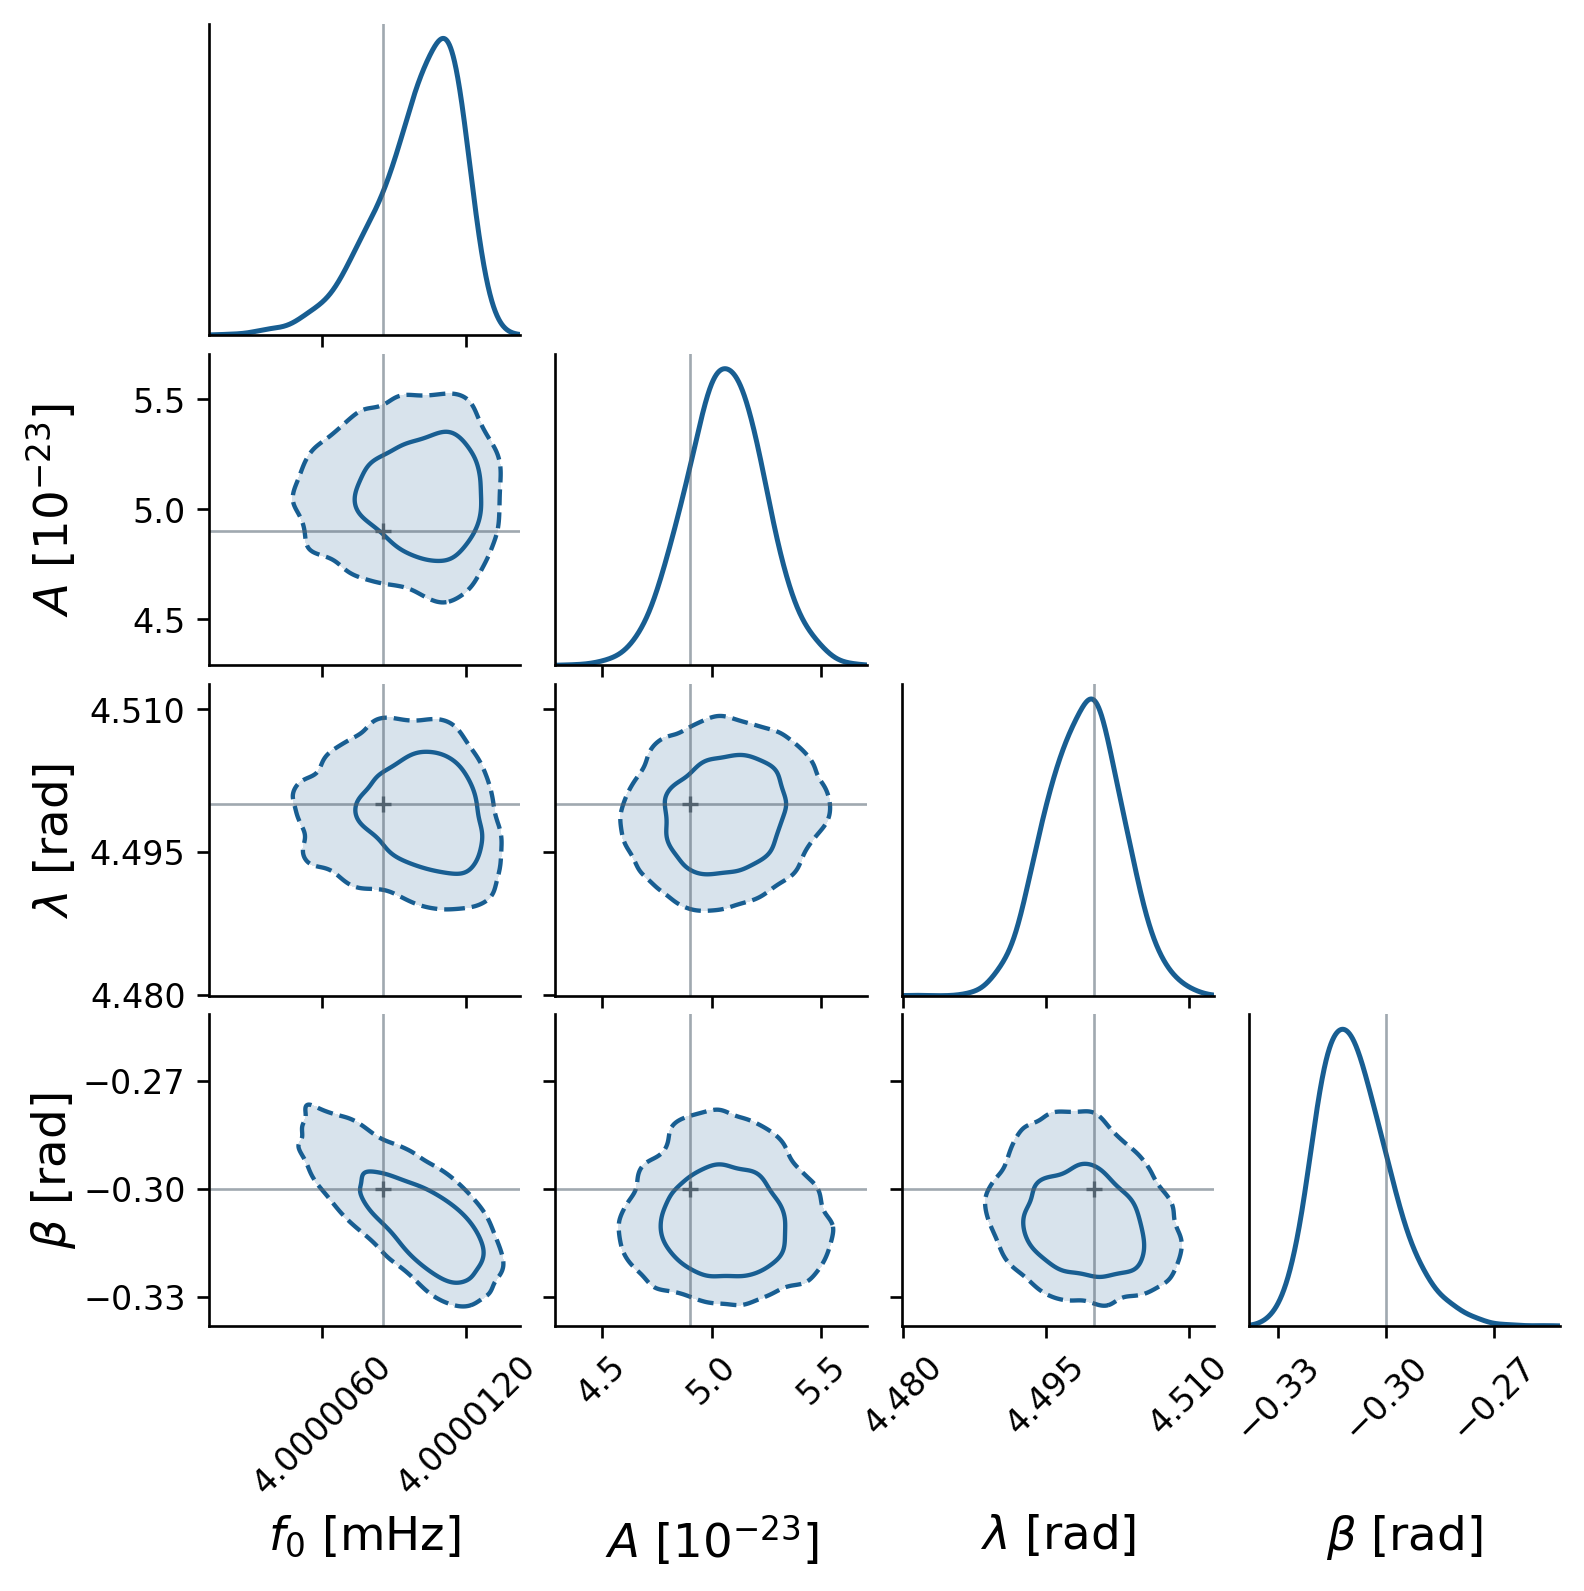

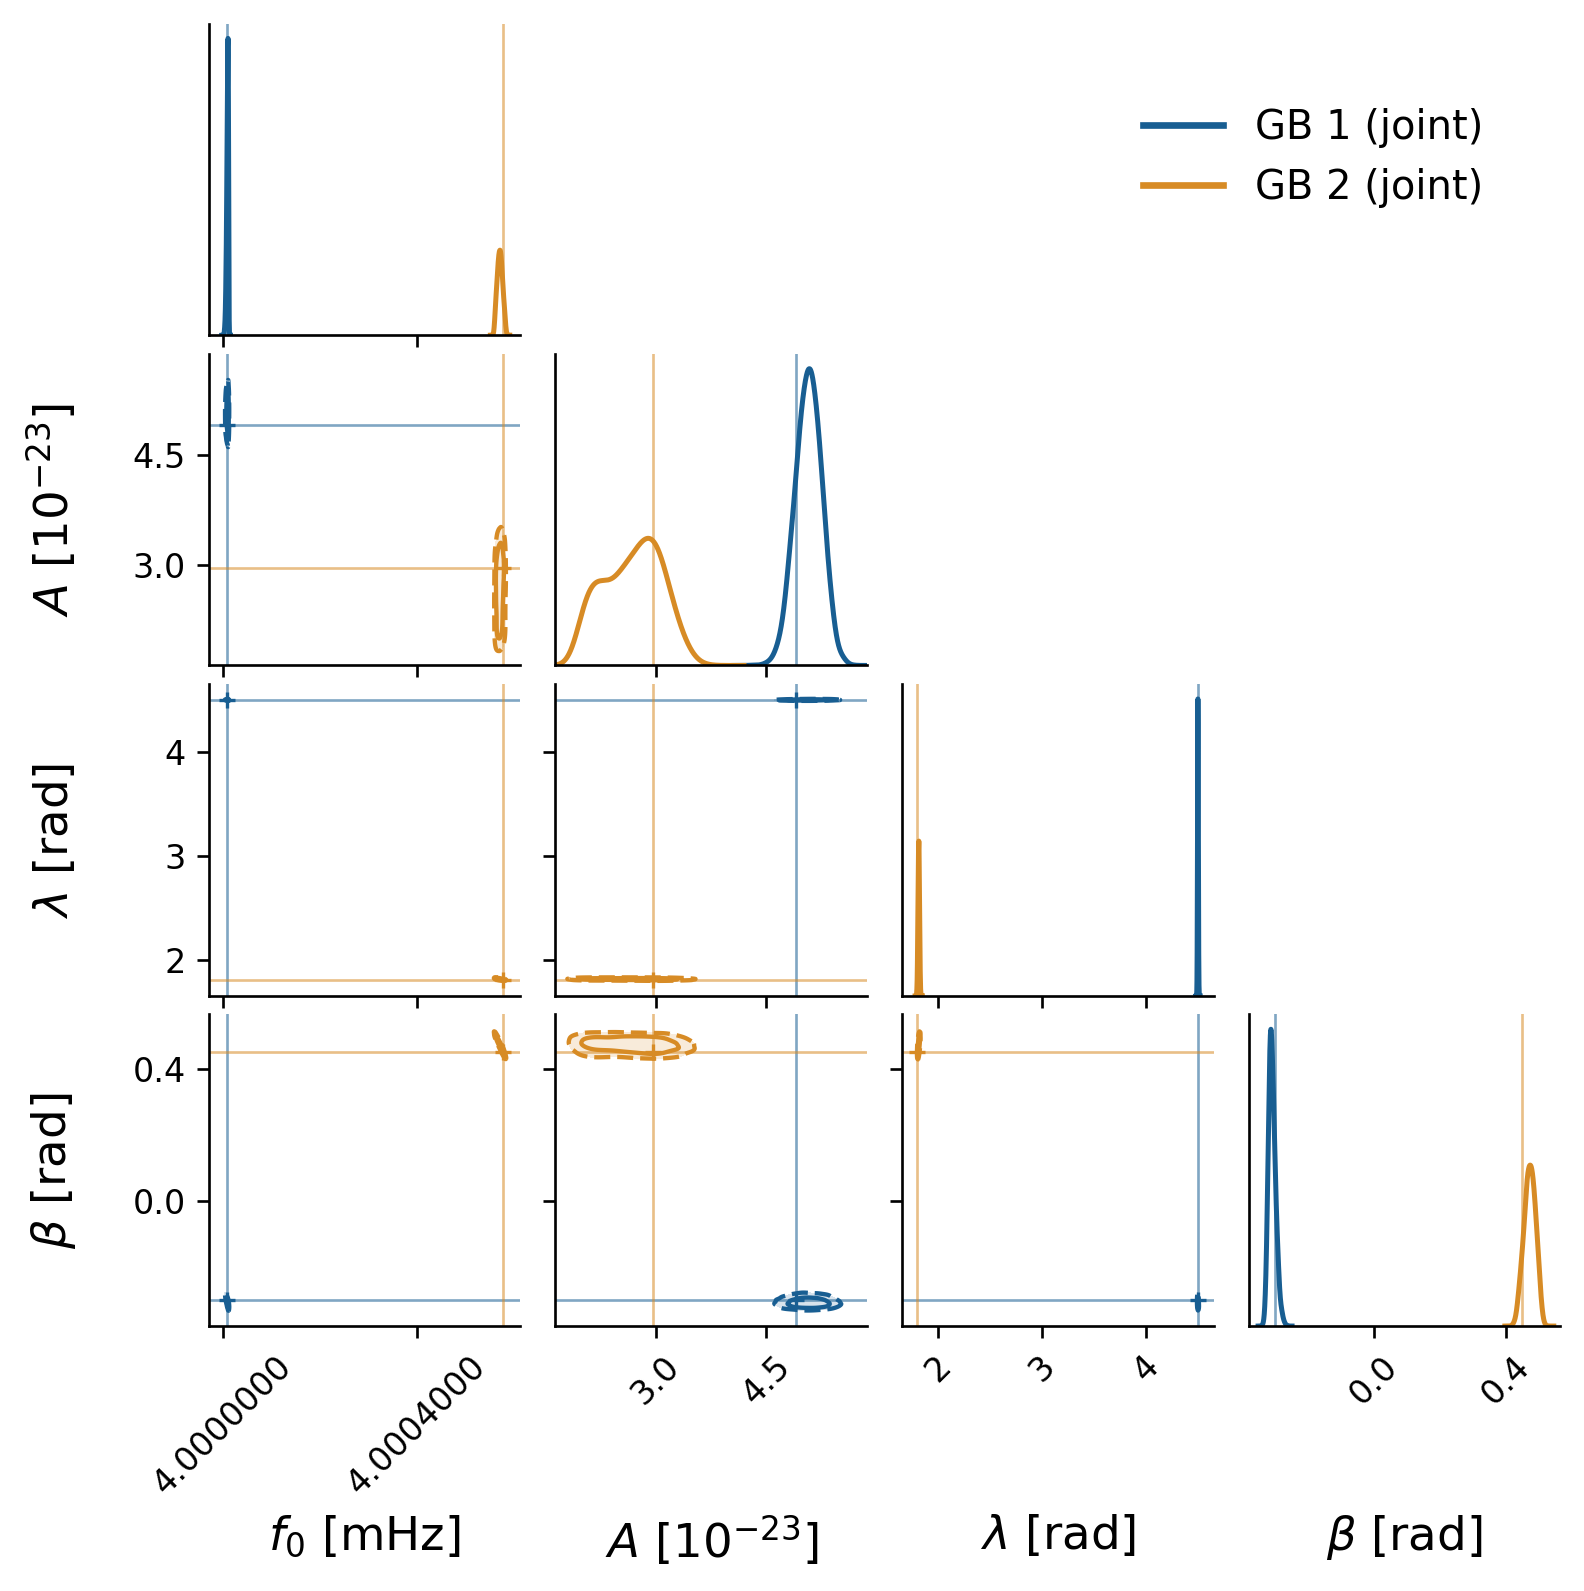

In [11]:
from tutorial_tools.corners import corner_plot
single_file = load_arrays("gb_matched_single_posterior.npz")
joint_file = load_arrays("gb_matched_double_midphase_posterior.npz")
single, joint = single_file["physical_samples"], joint_file["physical_samples"]
# Check a physical posterior draw against the native likelihood.
for likelihood, stored in zip(likelihoods, (single_file, joint_file)):
    for j, row in enumerate(stored["physical_samples"][0], 1):
        likelihood.parameters.update({f"{k}_{j}": row[i] for i, k in enumerate(names)})
    np.testing.assert_allclose(likelihood.log_likelihood(), stored["log_likelihood"][0], atol=1e-7)

single_view = single[:, 0, [0, 4, 2, 3]].copy()
joint_views = [joint[:, j, [0, 4, 2, 3]].copy() for j in (0, 1)]
for view in [single_view, *joint_views]:
    view[:, 0] *= 1e3
    view[:, 1] *= 1e23
labels = [r"$f_0$ [mHz]", r"$A$ [$10^{-23}$]", r"$\lambda$ [rad]", r"$\beta$ [rad]"]
truth = [[p["f0"]*1e3, p["A"]*1e23, p["longitude"], p["latitude"]] for p in injections]
corner_plot(single_view, labels, OUTPUT/"gb_single.png", truth[0], frequency_axes=(0,))
corner_plot(joint_views, labels, OUTPUT/"gb_joint.png", None,
            colors=["#185e92", "#d78b25"], legend=["GB 1 (joint)", "GB 2 (joint)"],
            truth_sets=truth, frequency_axes=(0,))
display(Image(filename=str(OUTPUT/"gb_single.png"), width=680))
display(Image(filename=str(OUTPUT/"gb_joint.png"), width=680))

## 6. Optional: run nessai to sample the posterior 


In [12]:
if RUN_INFERENCE:
    for label, likelihood, priors, nlive in zip(
            ("single", "joint"), likelihoods, prior_sets, (500, 800)):
        result = bilby.run_sampler(
            likelihood=likelihood, priors=priors, sampler="nessai",
            nlive=nlive, stopping=0.05, n_pool=NPROC, pytorch_threads=1, seed=20261121,
            outdir=str(OUTPUT/("gb_"+label)), label=label, resume=False, plot=False)
        result.posterior.to_csv(OUTPUT/("gb_"+label+"_posterior.csv"), index=False)
        result.plot_corner(save=True)


11:54 bilby INFO    : Running for label 'single', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/gb_single'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
11:54 bilby INFO    : Analysis priors:
11:54 bilby INFO    : f0_1=Uniform(minimum=0.003999916984874181, maximum=0.004000107113401066, name=None, latex_label=None, unit=None, boundary=None)
11:54 bilby INFO    : fdot0_1=Uniform(minimum=0, maximum=1.5e-15, name=None, latex_label=None, unit=None, boundary=None)
11:54 bilby INFO    : longitude_1=Uniform(minimum=4.1494617966939025, maximum=4.849461796693902, name=None, latex_label=None, unit=None, boundary=None)
11:54 bilby INFO    : 

11-04 11:54 nessai INFO    : Running Nessai version 0.14.0.post0
11-04 11:54 nessai INFO    : Starting multiprocessing pool with 12 processes


/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/nessai/utils/logging.py:133: FutureWarning: setup_logger is deprecated, use configure_logger instead
  warnings.warn(


11-04 11:54 nessai INFO    : Initialising nested sampler
11-04 11:54 nessai WARNING : Multiprocessing pool has already been configured.
11-04 11:54 nessai WARNING : Removing unused keyword arguments ({'ensemble_fraction', 'generate_augment', 'plot_history', 'step_kwargs', 'augment_dims', 'step_type', 'enforce_likelihood_threshold', 'plot_chain', 'max_n_clusters', 'n_marg', 'n_steps', 'marginalise_augment', 'n_accept'}) from kwargs for FlowProposal. These are valid keyword arguments but correspond to other proposal classes.
11-04 11:54 nessai INFO    : Passing kwargs to FlowProposal: {'training_config': None, 'poolsize': 1000, 'check_acceptance': False, 'max_poolsize_scale': 10, 'update_poolsize': True, 'accumulate_weights': False, 'save_training_data': False, 'reparameterisations': None, 'fallback_reparameterisation': 'zscore', 'use_default_reparameterisations': None, 'reverse_reparameterisations': False, 'map_to_unit_hypercube': False, 'latent_prior': 'truncated_gaussian', 'constant_v

11:57 bilby INFO    : Sampling time: 0:02:57.872134
11:57 bilby INFO    : Summary of results:
nsamples: 2448
ln_noise_evidence:    nan
ln_evidence: -343.709 +/-  0.231
ln_bayes_factor:    nan +/-  0.231

11:57 bilby INFO    : Running for label 'joint', output will be saved to '/Users/taijidatacenter/Desktop/PTASchool/Du_Minghui_Lecture/student_tutorials/outputs/gb_joint'
/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/bilby/core/utils/log.py:73: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  vdict[key] = str(getattr(sys.modules[key], "__version__", "N/A"))
11:57 bilby INFO    : Analysis priors:
11:57 bilby INFO    : f0_1=Uniform(minimum=0.003999916984874181, maximum=0.004000107113401066, name=None, latex_label=None, unit=None, boundary=None)
11:57 bilby INFO    : fdot0_1=Uniform(minimum=0, maximum=1.5e-15, name=None, latex_label=None

11-04 11:57 nessai INFO    : Running Nessai version 0.14.0.post0
11-04 11:57 nessai INFO    : Starting multiprocessing pool with 12 processes


/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/nessai/utils/logging.py:133: FutureWarning: setup_logger is deprecated, use configure_logger instead
  warnings.warn(


11-04 11:57 nessai INFO    : Initialising nested sampler
11-04 11:57 nessai WARNING : Multiprocessing pool has already been configured.
11-04 11:57 nessai WARNING : Removing unused keyword arguments ({'ensemble_fraction', 'generate_augment', 'plot_history', 'step_kwargs', 'augment_dims', 'step_type', 'enforce_likelihood_threshold', 'plot_chain', 'max_n_clusters', 'n_marg', 'n_steps', 'marginalise_augment', 'n_accept'}) from kwargs for FlowProposal. These are valid keyword arguments but correspond to other proposal classes.
11-04 11:57 nessai INFO    : Passing kwargs to FlowProposal: {'training_config': None, 'poolsize': 1000, 'check_acceptance': False, 'max_poolsize_scale': 10, 'update_poolsize': True, 'accumulate_weights': False, 'save_training_data': False, 'reparameterisations': None, 'fallback_reparameterisation': 'zscore', 'use_default_reparameterisations': None, 'reverse_reparameterisations': False, 'map_to_unit_hypercube': False, 'latent_prior': 'truncated_gaussian', 'constant_v

13:11 bilby INFO    : Sampling time: 1:13:44.569271
13:11 bilby INFO    : Summary of results:
nsamples: 5468
ln_noise_evidence:    nan
ln_evidence: -363.534 +/-  0.239
ln_bayes_factor:    nan +/-  0.239

